In [12]:
from pathlib import Path

import pandas as pd

PROJECT_ROOT = Path('/Users/adamswietek/Documents/NDSC_HiddenHousing')


def normalize_ain(values):
    """Return assessor parcel numbers as zero-padded 10-digit strings."""
    digits = values.astype('string').str.replace(r'\D', '', regex=True)
    digits = digits.where(digits.ne(''))
    return digits.str.zfill(10).where(lambda x: x.str.len().eq(10))

In [13]:
from pathlib import Path
import pandas as pd

violation_dir = Path(
    "/Users/adamswietek/Documents/NDSC_HiddenHousing/"
    "data/01_source/violations/Raw Data"
)

violations = pd.concat(
    [
        pd.read_csv(
            csv_path,
            dtype=str,
            low_memory=False,
        ).assign(
            source_file=csv_path.name,
            source_year=int(csv_path.name[:4]),
        )
        for csv_path in sorted(violation_dir.glob("*.csv"))
    ],
    ignore_index=True,
    sort=False,
)

print(violations.shape)
# violations.head()

(560730, 24)


In [14]:
complaints = pd.read_csv(
    PROJECT_ROOT / 'notebooks/methods/udu_violation_outcome_parcel_year.csv',
    dtype={'AIN': 'string'},
)
complaints['AIN'] = normalize_ain(complaints['AIN'])

In [15]:
method1_parcels = pd.read_csv(
    PROJECT_ROOT / 'data/03_processed/method_comparison/method1_floor_area_similarity_2017.csv',
    dtype={'AIN': 'string'},
)
method1_parcels['AIN'] = normalize_ain(method1_parcels['AIN'])

In [16]:
method1_parcels.columns

Index(['AIN', 'SpecificUseType', 'lariac_floor_area_continuous_sqft',
       'assessor_sqftmain', 'roof_type', 'lariac_to_assessor_ratio',
       'eligible_nonnegative_residual', 'potential_nonudu_2_5pct_by_use_type',
       'potential_nonudu_2_5pct_by_use_and_roof_type'],
      dtype='object')

In [17]:
CURRENT_UDU_REPORT = PROJECT_ROOT / 'data/01_source/UDU Report 02_10_2026.csv'
udu_report = pd.read_csv(
    CURRENT_UDU_REPORT, usecols=['assessor_parcel_number'], encoding='utf-8-sig'
)
udu_report['AIN'] = normalize_ain(udu_report['assessor_parcel_number'])
known_udu_ains = set(udu_report['AIN'].dropna())

print(f'Known UDU parcels: {len(known_udu_ains):,}')

Known UDU parcels: 443


In [18]:
COMPLAINT_HISTORY = (
    PROJECT_ROOT
    / 'data/01_source/violations/violations-2_with_nature_of_complaint_taxonomy_status (2).csv'
)

complaint_cases = pd.read_csv(
    COMPLAINT_HISTORY,
    usecols=['case_id', 'AIN'],
    dtype={'case_id': 'string', 'AIN': 'string'},
    encoding='utf-8-sig',
)
complaint_cases['AIN'] = normalize_ain(complaint_cases['AIN'])

known_udu_cases = (
    complaint_cases.loc[
        complaint_cases['AIN'].isin(known_udu_ains),
        ['AIN', 'case_id'],
    ]
    .dropna(subset=['case_id'])
    .drop_duplicates()
    .sort_values(['AIN', 'case_id'])
    .reset_index(drop=True)
)

print(f'Known UDU parcels with a complaint case: {known_udu_cases["AIN"].nunique():,}')
print(f'Unique complaint cases: {known_udu_cases["case_id"].nunique():,}')
known_udu_cases

Known UDU parcels with a complaint case: 289
Unique complaint cases: 1,346


,AIN,case_id
0,2102021039,132379
1,2102021039,132582
2,2102021039,169096
3,2102021039,201930
4,2102021039,21719
...,...,...
1341,7460030022,7611
1342,7462019039,737532
1343,7462021012,326850
1344,7462021012,338836


In [19]:
# Match known UDU parcels to the complete 2005-2023 violations history.
# The raw files changed field names beginning in 2022.
wide_ain = violations['APN'].fillna(violations['apn'])
wide_case_id = violations['Case No.'].fillna(violations['crisCaseID'])

wide_violation_matches = pd.DataFrame({
    'AIN': normalize_ain(wide_ain),
    'case_id': wide_case_id.astype('string').str.strip(),
    'year': pd.to_numeric(violations['source_year'], errors='coerce').astype('Int64'),
    'source_file': violations['source_file'],
})

wide_violation_matches = wide_violation_matches.loc[
    wide_violation_matches['AIN'].isin(known_udu_ains)
    & wide_violation_matches['case_id'].notna()
    & wide_violation_matches['case_id'].ne('')
].copy()

known_udu_cases_wide = (
    wide_violation_matches
    .groupby(['AIN', 'case_id'], as_index=False)
    .agg(
        first_year=('year', 'min'),
        last_year=('year', 'max'),
        violation_observations=('case_id', 'size'),
    )
    .sort_values(['AIN', 'first_year', 'case_id'])
    .reset_index(drop=True)
)

complaint_history_pairs = pd.MultiIndex.from_frame(known_udu_cases[['AIN', 'case_id']])
wide_pairs = pd.MultiIndex.from_frame(known_udu_cases_wide[['AIN', 'case_id']])
known_udu_cases_wide['in_complaint_history'] = wide_pairs.isin(complaint_history_pairs)

print(f'Raw violation observations searched: {len(violations):,}')
print(f'Known UDU parcels with a raw violation case: {known_udu_cases_wide["AIN"].nunique():,}')
print(f'Unique raw violation cases: {known_udu_cases_wide["case_id"].nunique():,}')
print(f'Additional parcel-case matches beyond complaint history: {(~known_udu_cases_wide["in_complaint_history"]).sum():,}')
known_udu_cases_wide

Raw violation observations searched: 560,730
Known UDU parcels with a raw violation case: 426
Unique raw violation cases: 2,915
Additional parcel-case matches beyond complaint history: 1,569


,AIN,case_id,first_year,last_year,violation_observations,in_complaint_history
0,2102021039,21719,2005,2005,1,True
1,2102021039,27418,2005,2005,1,True
2,2102021039,132379,2007,2007,1,True
3,2102021039,132582,2007,2007,1,True
4,2102021039,135665,2007,2007,1,False
...,...,...,...,...,...,...
2910,7467027011,3245,2005,2005,1,False
2911,7467027011,175403,2008,2008,1,False
2912,7467027011,441376,2013,2013,1,False
2913,7467027011,583205,2016,2016,1,False


In [20]:
known_udu_cases_wide[['AIN','case_id']].to_csv('known_udu_ains_and_cases.csv')

In [21]:
known_udu_details_fp = '/Users/adamswietek/Documents/NDSC_HiddenHousing/notebooks/methods/known_udu_case_details.csv'

known_udu_details = pd.read_csv(known_udu_details_fp)


In [22]:
known_udu_details

,case_id,ain_csv,apn_page,apn_match,case_type,inspector,total_units,council_district,census_tract,regional_office,official_address,nature_of_complaint,activity_n,activity_first_date,activity_last_date,activity_list,fetch_status,http_code,fetched_at_utc
0,21719,2102021039,2102021039,yes,Complaint,Ricky Reisner,141.0,4.0,131400.0,Valley Regional Office,"7722 N RESEDA BLVD, RESEDA 91335",Peeling paint & mold in the bathroom.,5,07/15/2005 12:00:00 AM,08/23/2005 04:02:00 PM,08/23/2005 04:02:00 PM | Site Visit/Initial In...,ok,200,2026-11-05T23:02:28Z
1,27418,2102021039,2102021039,yes,Complaint,Dwight Teske,141.0,4.0,131400.0,Valley Regional Office,"7722 N RESEDA BLVD, RESEDA 91335",nails coming out of the carpet,8,08/29/2005 12:00:00 AM,11/18/2005 10:44:00 AM,11/18/2005 10:44:00 AM | Complaint Closed; 11/...,ok,200,2026-11-05T23:04:06Z
2,132379,2102021039,2102021039,yes,Complaint,Janet Murphy,141.0,4.0,131400.0,Valley Regional Office,"7722 N RESEDA BLVD, RESEDA 91335",Lack of adequate flow of hot and/or cold runni...,8,04/20/2007 12:00:00 AM,06/04/2007 09:00:00 AM,06/04/2007 09:00:00 AM | Complaint Closed; 06/...,ok,200,2026-11-06T00:14:03Z
3,132582,2102021039,2102021039,yes,Complaint,Dwight Teske,141.0,4.0,131400.0,Valley Regional Office,"7722 N RESEDA BLVD, RESEDA 91335","Electrical conduit damaged/loose, Broken or mi...",5,04/23/2007 12:00:00 AM,05/23/2007 08:48:00 AM,05/23/2007 08:48:00 AM | Complaint Closed; 05/...,ok,200,2026-11-06T00:17:13Z
4,169096,2102021039,2102021039,yes,Complaint,Dwight Teske,141.0,4.0,131400.0,Valley Regional Office,"7722 N RESEDA BLVD, RESEDA 91335","Vacant units not secure, unclean and/or unsani...",5,12/10/2007 12:00:00 AM,01/03/2008 07:18:00 AM,01/03/2008 07:18:00 AM | Complaint Closed; 01/...,ok,200,2026-11-06T00:43:36Z
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2910,441376,7467027011,7467027011,yes,SCEP,Lee Bruce,8.0,15.0,297601.0,South Regional Office,"4015 S PACIFIC AVE, Los Angeles 90731",NaN,2,08/27/2013 09:08:00 AM,08/27/2013 10:08:00 AM,08/27/2013 10:08:00 AM | No Violations Observe...,ok,200,2026-11-07T05:56:41Z
2911,751482,7462021012,7462021012,yes,SCEP,George Terranova,5.0,15.0,297201.0,South Regional Office,"723 W 20TH ST, SAN PEDRO 90731",NaN,5,10/14/2020 09:00:00 AM,12/02/2020 11:59:00 AM,12/02/2020 11:59:00 AM | All Violations Resolv...,ok,200,2026-11-07T05:56:42Z
2912,577325,7467017004,7467017004,yes,SCEP,Andres Moran,4.0,15.0,297601.0,South Regional Office,"3700 S BLUFF PL, SAN PEDRO 90731",NaN,9,07/13/2016 10:25:00 AM,09/12/2018 10:00:00 AM,09/12/2018 10:00:00 AM | All Violations Resolv...,ok,200,2026-11-07T05:56:42Z
2913,583205,7467027011,7467027011,yes,SCEP,Alan Christensen,8.0,15.0,297601.0,South Regional Office,"4015 S PACIFIC AVE, Los Angeles 90731",NaN,2,08/22/2016 12:22:00 PM,08/22/2016 01:17:00 PM,08/22/2016 01:17:00 PM | No Violations Observe...,ok,200,2026-11-07T05:56:43Z


In [23]:
# Clean fields and derive case-history indicators.
known_udu_details['case_id'] = known_udu_details['case_id'].astype('string')
known_udu_details['AIN'] = normalize_ain(known_udu_details['ain_csv'])
known_udu_details['first_date'] = pd.to_datetime(
    known_udu_details['activity_first_date'], errors='coerce', format='mixed'
)
known_udu_details['last_date'] = pd.to_datetime(
    known_udu_details['activity_last_date'], errors='coerce', format='mixed'
)
known_udu_details['first_year'] = known_udu_details['first_date'].dt.year.astype('Int64')
known_udu_details['case_duration_days'] = (
    known_udu_details['last_date'] - known_udu_details['first_date']
).dt.days

activity_text = known_udu_details['activity_list'].fillna('').str.lower()
status_patterns = {
    'order_issued': 'order issued to property owner',
    'no_violations_observed': 'no violations observed',
    'violations_corrected': 'violations corrected',
    'complaint_closed': 'complaint closed',
    'referred': r'referred|referral',
}
for column, pattern in status_patterns.items():
    known_udu_details[column] = activity_text.str.contains(pattern, regex=True)

known_udu_summary = pd.DataFrame({
    'value': [
        len(known_udu_details),
        known_udu_details['case_id'].nunique(),
        known_udu_details['AIN'].nunique(),
        len(known_udu_ains - set(known_udu_details['AIN'].dropna())),
        known_udu_details['nature_of_complaint'].notna().sum(),
        known_udu_details['first_date'].min(),
        known_udu_details['first_date'].max(),
    ]
}, index=[
    'case records',
    'unique case IDs',
    'known UDU parcels represented',
    'known UDU parcels without case details',
    'cases with nature-of-complaint text',
    'earliest first activity',
    'latest first activity',
])
known_udu_summary

,value
case records,2915
unique case IDs,2915
known UDU parcels represented,426
known UDU parcels without case details,17
cases with nature-of-complaint text,1361
earliest first activity,2005-03-02 00:00:00
latest first activity,2023-12-26 09:00:00


### Case composition and parcels with the most history

In [24]:
case_type_summary = (
    known_udu_details['case_type']
    .value_counts(dropna=False)
    .rename_axis('case_type')
    .to_frame('cases')
)
case_type_summary['share'] = case_type_summary['cases'] / len(known_udu_details)

status_summary = pd.DataFrame({
    'cases': known_udu_details[list(status_patterns)].sum(),
    'share': known_udu_details[list(status_patterns)].mean(),
}).sort_values('cases', ascending=False)

parcel_case_summary = (
    known_udu_details.groupby('AIN', as_index=False)
    .agg(
        case_count=('case_id', 'nunique'),
        complaint_cases=('case_type', lambda x: x.eq('Complaint').sum()),
        first_activity=('first_date', 'min'),
        last_activity=('last_date', 'max'),
        total_units=('total_units', 'max'),
        official_address=('official_address', 'first'),
    )
    .sort_values('case_count', ascending=False)
)

display(case_type_summary.style.format({'share': '{:.1%}'}))
display(status_summary.style.format({'share': '{:.1%}'}))
display(parcel_case_summary.head(20))

,cases,share
case_type,,
SCEP,1478,50.7%
Complaint,1346,46.2%
TIER 2,81,2.8%
Task Force,7,0.2%
Home,3,0.1%


,cases,share
order_issued,1783,61.2%
complaint_closed,1276,43.8%
no_violations_observed,1063,36.5%
referred,425,14.6%
violations_corrected,402,13.8%


,AIN,case_count,complaint_cases,first_activity,last_activity,total_units,official_address
280,5402023019,61,56,2005-08-09 00:00:00,2023-06-29 09:30:00,53.0,"2416 W BELLEVUE AVE, Los Angeles 90026"
63,2653015040,53,49,2006-03-20 10:17:00,2023-07-18 14:01:00,42.0,"8539 N WILLIS AVE, PANORAMA CITY 91402"
62,2653015039,52,48,2005-07-21 00:00:00,2023-12-22 10:57:00,42.0,"8529 N WILLIS AVE, PANORAMA CITY 91402"
0,2102021039,43,39,2005-07-15 00:00:00,2023-12-26 14:19:00,141.0,"7722 N RESEDA BLVD, RESEDA 91335"
1,2138021032,41,38,2005-10-04 00:00:00,2023-12-18 10:56:00,34.0,None
326,5521023008,30,27,2005-11-01 00:00:00,2020-04-23 14:19:00,69.0,"437 N ARDMORE AVE, Los Angeles 90004"
344,5539021005,28,24,2006-01-10 00:00:00,2022-06-23 09:44:00,93.0,"4150 W MARATHON ST, Los Angeles 90029"
220,5113024019,26,23,2005-12-23 00:00:00,2026-08-13 12:21:00,14.0,"259 E 41ST PL, Los Angeles 90011"
14,2231006049,25,22,2005-10-03 00:00:00,2022-09-14 10:49:00,71.0,"6626 N HAYVENHURST AVE, VAN NUYS 91406"
2,2139006075,25,21,2006-04-19 00:00:00,2023-08-02 09:56:00,95.0,"6644 N GLADE AVE, CANOGA PARK 91303"


### Complaint taxonomy among known UDU cases

Taxonomy is available for complaint cases with scraped complaint text; SCEP and other administrative cases generally have no complaint taxonomy.

In [25]:
taxonomy_columns = [
    'case_id', 'relates_to_unpermitted_structure', 'dwelling_specific',
    'complaint_category', 'order_issued_ever', 'no_violations_observed_ever',
]
complaint_taxonomy = pd.read_csv(
    COMPLAINT_HISTORY,
    usecols=taxonomy_columns,
    dtype={'case_id': 'string'},
).drop_duplicates('case_id')

known_udu_details_enriched = known_udu_details.merge(
    complaint_taxonomy, on='case_id', how='left', validate='1:1'
)
known_udu_details_enriched['complaint_category_display'] = (
    known_udu_details_enriched['complaint_category']
    .fillna('No complaint taxonomy')
)

known_udu_taxonomy_summary = (
    known_udu_details_enriched['complaint_category_display']
    .value_counts()
    .rename_axis('complaint_category')
    .to_frame('cases')
)
known_udu_taxonomy_summary['share_all_cases'] = (
    known_udu_taxonomy_summary['cases'] / len(known_udu_details_enriched)
)

print(
    'Cases classified as related to an unpermitted structure:',
    int(known_udu_details_enriched['relates_to_unpermitted_structure'].eq(True).sum()),
)
print(
    'Cases classified as both unpermitted-related and dwelling-specific:',
    int((
        known_udu_details_enriched['relates_to_unpermitted_structure'].eq(True)
        & known_udu_details_enriched['dwelling_specific'].eq(True)
    ).sum()),
)
known_udu_taxonomy_summary.style.format({'share_all_cases': '{:.1%}'})

Cases classified as related to an unpermitted structure: 474
Cases classified as both unpermitted-related and dwelling-specific: 130


,cases,share_all_cases
complaint_category,,
No complaint taxonomy,1569,53.8%
not_unpermitted_related,872,29.9%
work_without_permits,139,4.8%
unapproved_unit,129,4.4%
other_unpermitted,97,3.3%
unapproved_trade_work,67,2.3%
change_of_use,36,1.2%
unpermitted_construction,3,0.1%
unpermitted_addition,2,0.1%


### Known UDU case-history overview

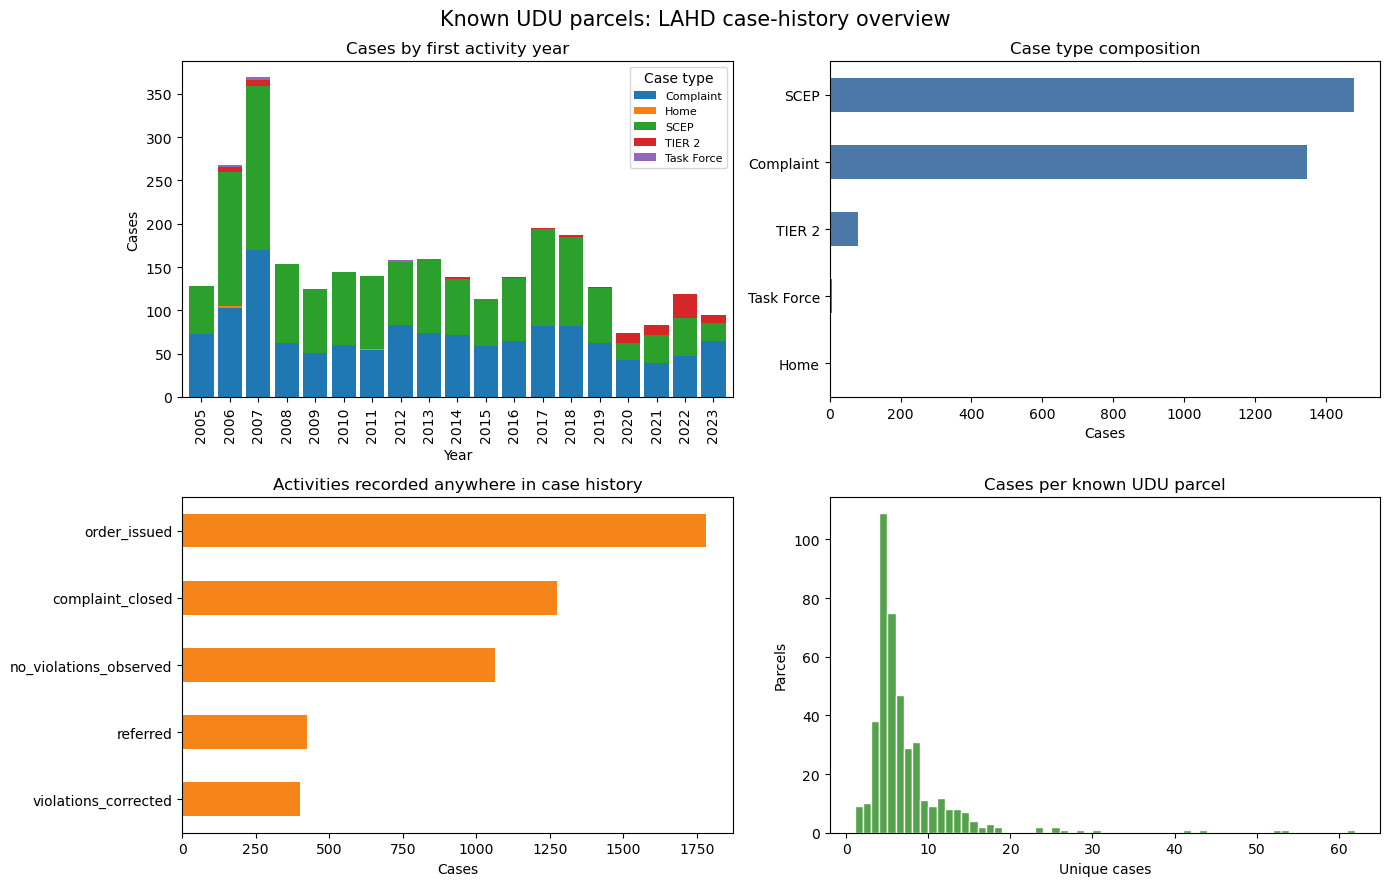

In [26]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

year_case_type = (
    known_udu_details.dropna(subset=['first_year'])
    .groupby(['first_year', 'case_type'])
    .size()
    .unstack(fill_value=0)
)
year_case_type.plot.bar(stacked=True, ax=axes[0, 0], width=0.85)
axes[0, 0].set(title='Cases by first activity year', xlabel='Year', ylabel='Cases')
axes[0, 0].legend(title='Case type', fontsize=8)

case_type_summary.sort_values('cases')['cases'].plot.barh(ax=axes[0, 1], color='#4C78A8')
axes[0, 1].set(title='Case type composition', xlabel='Cases', ylabel='')

status_summary.sort_values('cases')['cases'].plot.barh(ax=axes[1, 0], color='#F58518')
axes[1, 0].set(title='Activities recorded anywhere in case history', xlabel='Cases', ylabel='')

parcel_case_summary['case_count'].plot.hist(
    bins=range(1, int(parcel_case_summary['case_count'].max()) + 2),
    ax=axes[1, 1], color='#54A24B', edgecolor='white'
)
axes[1, 1].set(title='Cases per known UDU parcel', xlabel='Unique cases', ylabel='Parcels')

fig.suptitle('Known UDU parcels: LAHD case-history overview', fontsize=15)
fig.tight_layout()
plt.show()

### Examples of multiple cases on the same parcel

AIN identifies the parcel; `case_id` identifies an individual LAHD case. Therefore, one AIN can legitimately appear with many distinct case IDs over time.

In [ ]:
multi_case_parcels = parcel_case_summary.query('case_count > 1').copy()
example_ains = multi_case_parcels.head(5)['AIN'].tolist()

multi_case_examples = (
    known_udu_details.loc[
        known_udu_details['AIN'].isin(example_ains),
        [
            'AIN', 'case_id', 'case_type', 'first_date',
            'official_address', 'nature_of_complaint',
        ],
    ]
    .sort_values(['AIN', 'first_date', 'case_id'])
    .groupby('AIN', group_keys=False)
    .head(10)
    .reset_index(drop=True)
)

print(
    f'{len(multi_case_parcels):,} of {len(parcel_case_summary):,} known UDU parcels '    'have more than one distinct case.'
)
display(
    multi_case_parcels.head(10)[
        ['AIN', 'case_count', 'complaint_cases', 'first_activity',
         'last_activity', 'total_units', 'official_address']
    ]
)
display(multi_case_examples)